In [ ]:
!pip install lime scikit-image

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

model_path = "/content/drive/MyDrive/<your-folder>/mobilenetv2_combined_v2.h5"
model = load_model(model_path)

Mounted at /content/drive


NameError: name 'load_model' is not defined

In [ ]:
import glob
matches = glob.glob("/content/drive/MyDrive/**/mobilenetv2_combined_v2.h5", recursive=True)
print(matches)

['/content/drive/MyDrive/AgroScan-data-V2/mobilenetv2_combined_v2.h5']


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from tensorflow.keras.models import load_model
from lime import lime_image
from skimage.segmentation import mark_boundaries

model = load_model("/content/drive/MyDrive/AgroScan-data-V2/mobilenetv2_combined_v2.h5")

ModuleNotFoundError: No module named 'lime'

In [ ]:
print(model.input_shape)

In [ ]:
IMG_SIZE = (224, 224)

CLASS_NAMES = [
    "Pepper__bell___Bacterial_spot",
    "Potato___Early_blight",
    "Potato___Late_blight",
    "Tomato_Bacterial_spot",
    "Tomato_Early_blight",
    "Tomato_Late_blight",
    "Tomato_Septoria_leaf_spot",
    "Tomato_healthy",
]

def preprocess(batch):
    return batch / 255.0

In [ ]:
def load_img(path):
    img = Image.open(path).convert("RGB").resize(IMG_SIZE)
    return np.array(img)

In [ ]:
def predict_fn(images):
    batch = preprocess(images.astype("float32"))
    return model.predict(batch, verbose=0)

In [ ]:
import glob
all_imgs = glob.glob("/content/drive/MyDrive/AgroScan-data-V2/**/*.jpg", recursive=True)
all_imgs += glob.glob("/content/drive/MyDrive/AgroScan-data-V2/**/*.JPG", recursive=True)
all_imgs += glob.glob("/content/drive/MyDrive/AgroScan-data-V2/**/*.png", recursive=True)
print(len(all_imgs))
for i in range(min(10, len(all_imgs))):
    print(i, all_imgs[i])

In [ ]:
img_path = all_imgs[0]   # change the index to a PlantDoc test image
img = load_img(img_path)
p = predict_fn(np.expand_dims(img, axis=0))[0]
print(img_path)
print(CLASS_NAMES[int(np.argmax(p))], round(float(np.max(p)) * 100, 1))

In [ ]:
explainer = lime_image.LimeImageExplainer()
explanation = explainer.explain_instance(
    img,
    predict_fn,
    top_labels=1,
    hide_color=0,
    num_samples=500,
)

In [ ]:
label = explanation.top_labels[0]
probs = predict_fn(np.expand_dims(img, axis=0))[0]

temp, mask = explanation.get_image_and_mask(
    label, positive_only=True, num_features=5, hide_rest=False
)

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(img)
axes[0].set_title("Original")
axes[1].imshow(mark_boundaries(temp / 255.0, mask))
axes[1].set_title(CLASS_NAMES[label] + " (" + str(round(float(probs[label]) * 100, 1)) + "%)")
for i in range(len(axes)):
    axes[i].axis("off")
plt.show()

In [ ]:
import os
out_dir = "/content/drive/MyDrive/AgroScan-data-V2/lime_figures"
os.makedirs(out_dir, exist_ok=True)

paths = [
    all_imgs[0],    # replace with a correctly predicted image
    all_imgs[1],    # replace with the misclassified late blight image
    all_imgs[2],    # replace with a low-confidence image
]

for i in range(len(paths)):
    im = load_img(paths[i])
    exp = explainer.explain_instance(im, predict_fn, top_labels=1,
                                     hide_color=0, num_samples=500)
    lbl = exp.top_labels[0]
    pr = predict_fn(np.expand_dims(im, axis=0))[0]
    t, m = exp.get_image_and_mask(lbl, positive_only=True,
                                  num_features=5, hide_rest=False)

    fig, axes = plt.subplots(1, 2, figsize=(8, 4))
    axes[0].imshow(im)
    axes[0].set_title("Original")
    axes[1].imshow(mark_boundaries(t / 255.0, m))
    axes[1].set_title(CLASS_NAMES[lbl] + " (" + str(round(float(pr[lbl]) * 100, 1)) + "%)")
    for j in range(len(axes)):
        axes[j].axis("off")
    plt.savefig(out_dir + "/lime_example_" + str(i + 1) + ".png", dpi=150, bbox_inches="tight")
    plt.show()

In [ ]:
import os
rows = []
for i in range(min(40, len(all_imgs))):
    im = load_img(all_imgs[i])
    pr = predict_fn(np.expand_dims(im, axis=0))[0]
    pred = CLASS_NAMES[int(np.argmax(pr))]
    true = os.path.basename(os.path.dirname(all_imgs[i]))
    rows.append((i, true, pred, round(float(np.max(pr)) * 100, 1)))
for r in rows:
    print(r)

In [ ]:
name_map = {
    "Bell_pepper leaf spot": "Pepper__bell___Bacterial_spot",
    "Potato leaf early blight": "Potato___Early_blight",
    "Potato leaf late blight": "Potato___Late_blight",
    "Tomato leaf bacterial spot": "Tomato_Bacterial_spot",
    "Tomato Early blight leaf": "Tomato_Early_blight",
    "Tomato leaf late blight": "Tomato_Late_blight",
    "Tomato Septoria leaf spot": "Tomato_Septoria_leaf_spot",
    "Tomato leaf": "Tomato_healthy",
}

test_imgs = []
for i in range(len(all_imgs)):
    p = all_imgs[i]
    if "plantdoc_subset" in p:
        folder = os.path.basename(os.path.dirname(p))
        if folder in name_map:
            test_imgs.append((p, name_map[folder]))
print(len(test_imgs))

In [ ]:
rows = []
for i in range(len(test_imgs)):
    im = load_img(test_imgs[i][0])
    pr = predict_fn(np.expand_dims(im, axis=0))[0]
    pred = CLASS_NAMES[int(np.argmax(pr))]
    rows.append((i, test_imgs[i][1], pred, round(float(np.max(pr)) * 100, 1)))
for i in range(len(rows)):
    print(rows[i])

NameError: name 'test_imgs' is not defined

In [ ]:
!pip install -q lime scikit-image

from google.colab import drive
drive.mount('/content/drive')

import os, glob
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from tensorflow.keras.models import load_model
from lime import lime_image
from skimage.segmentation import mark_boundaries

model = load_model("/content/drive/MyDrive/AgroScan-data-V2/mobilenetv2_combined_v2.h5")

IMG_SIZE = (224, 224)
CLASS_NAMES = [
    "Pepper__bell___Bacterial_spot",
    "Potato___Early_blight",
    "Potato___Late_blight",
    "Tomato_Bacterial_spot",
    "Tomato_Early_blight",
    "Tomato_Late_blight",
    "Tomato_Septoria_leaf_spot",
    "Tomato_healthy",
]

def preprocess(batch):
    return batch / 255.0

def load_img(path):
    img = Image.open(path).convert("RGB").resize(IMG_SIZE)
    return np.array(img)

def predict_fn(images):
    batch = preprocess(images.astype("float32"))
    return model.predict(batch, verbose=0)

all_imgs = []
for ext in ["jpg", "JPG", "jpeg", "png"]:
    all_imgs += glob.glob("/content/drive/MyDrive/AgroScan-data-V2/**/*." + ext, recursive=True)
print(len(all_imgs))

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 5.2 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
Mounted at /content/drive


20276


In [ ]:
folders = {}
for i in range(len(all_imgs)):
    p = all_imgs[i]
    key = os.path.dirname(os.path.dirname(p)) + "  >>  " + os.path.basename(os.path.dirname(p))
    folders[key] = folders.get(key, 0) + 1
for k in sorted(folders):
    print(folders[k], k)

3 /content/drive/MyDrive/AgroScan-data-V2  >>  lime_figures
1 /content/drive/MyDrive/AgroScan-data-V2  >>  plantdoc
1307 /content/drive/MyDrive/AgroScan-data-V2/combined_subset_v2  >>  Pepper__bell___Bacterial_spot
1545 /content/drive/MyDrive/AgroScan-data-V2/combined_subset_v2  >>  Potato___Early_blight
1485 /content/drive/MyDrive/AgroScan-data-V2/combined_subset_v2  >>  Potato___Late_blight
2632 /content/drive/MyDrive/AgroScan-data-V2/combined_subset_v2  >>  Tomato_Bacterial_spot
1395 /content/drive/MyDrive/AgroScan-data-V2/combined_subset_v2  >>  Tomato_Early_blight
2414 /content/drive/MyDrive/AgroScan-data-V2/combined_subset_v2  >>  Tomato_Late_blight
2471 /content/drive/MyDrive/AgroScan-data-V2/combined_subset_v2  >>  Tomato_Septoria_leaf_spot
1866 /content/drive/MyDrive/AgroScan-data-V2/combined_subset_v2  >>  Tomato_healthy
1 /content/drive/MyDrive/AgroScan-data-V2/plantdoc  >>  PlantDoc-Dataset
10 /content/drive/MyDrive/AgroScan-data-V2/plantdoc/PlantDoc-Dataset/test  >>  Apple

In [ ]:
name_map = {
    "Bell_pepper leaf spot": "Pepper__bell___Bacterial_spot",
    "Potato leaf early blight": "Potato___Early_blight",
    "Potato leaf late blight": "Potato___Late_blight",
    "Tomato leaf bacterial spot": "Tomato_Bacterial_spot",
    "Tomato Early blight leaf": "Tomato_Early_blight",
    "Tomato leaf late blight": "Tomato_Late_blight",
    "Tomato Septoria leaf spot": "Tomato_Septoria_leaf_spot",
    "Tomato leaf": "Tomato_healthy",
}

test_imgs = []
for i in range(len(all_imgs)):
    p = all_imgs[i]
    if "/AgroScan-data-V2/plantdoc/test/" in p:
        folder = os.path.basename(os.path.dirname(p))
        if folder in name_map:
            test_imgs.append((p, name_map[folder]))
print("test images:", len(test_imgs))

rows = []
correct = 0
for i in range(len(test_imgs)):
    im = load_img(test_imgs[i][0])
    pr = predict_fn(np.expand_dims(im, axis=0))[0]
    pred = CLASS_NAMES[int(np.argmax(pr))]
    conf = round(float(np.max(pr)) * 100, 1)
    rows.append((i, test_imgs[i][1], pred, conf))
    if pred == test_imgs[i][1]:
        correct = correct + 1
    print(rows[i])

print("accuracy:", round(correct / len(test_imgs) * 100, 2), "%")

test images: 72
(0, 'Pepper__bell___Bacterial_spot', 'Pepper__bell___Bacterial_spot', 69.8)
(1, 'Pepper__bell___Bacterial_spot', 'Tomato_Late_blight', 64.6)
(2, 'Pepper__bell___Bacterial_spot', 'Tomato_Bacterial_spot', 41.6)
(3, 'Pepper__bell___Bacterial_spot', 'Tomato_Septoria_leaf_spot', 99.7)
(4, 'Pepper__bell___Bacterial_spot', 'Pepper__bell___Bacterial_spot', 73.8)
(5, 'Pepper__bell___Bacterial_spot', 'Pepper__bell___Bacterial_spot', 98.0)
(6, 'Pepper__bell___Bacterial_spot', 'Pepper__bell___Bacterial_spot', 97.2)
(7, 'Pepper__bell___Bacterial_spot', 'Tomato_Septoria_leaf_spot', 82.1)
(8, 'Pepper__bell___Bacterial_spot', 'Tomato_Bacterial_spot', 48.5)
(9, 'Potato___Early_blight', 'Potato___Late_blight', 82.5)
(10, 'Potato___Early_blight', 'Potato___Late_blight', 63.6)
(11, 'Potato___Early_blight', 'Potato___Early_blight', 66.1)
(12, 'Potato___Early_blight', 'Tomato_Early_blight', 40.5)
(13, 'Potato___Early_blight', 'Tomato_Early_blight', 79.5)
(14, 'Potato___Early_blight', 'Potato

  0%|          | 0/1000 [00:00<?, ?it/s]

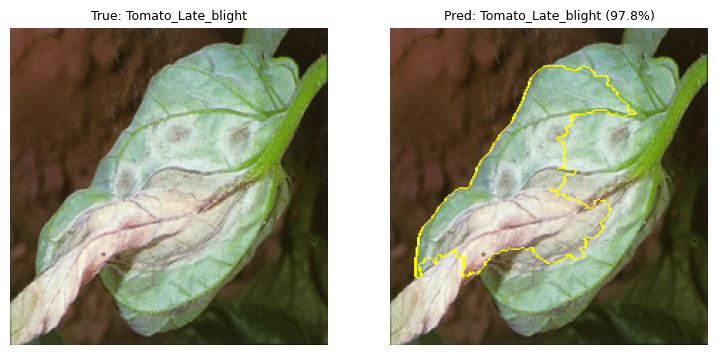

  0%|          | 0/1000 [00:00<?, ?it/s]

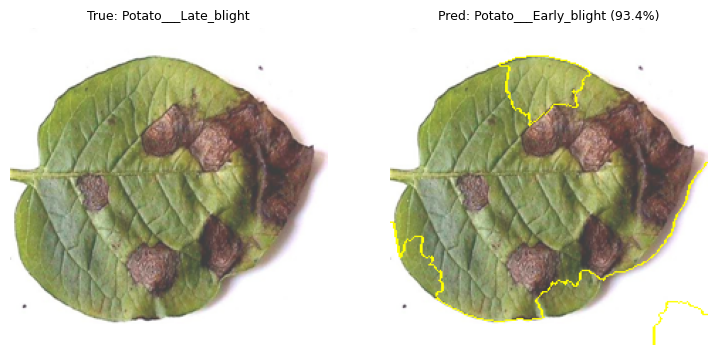

  0%|          | 0/1000 [00:00<?, ?it/s]

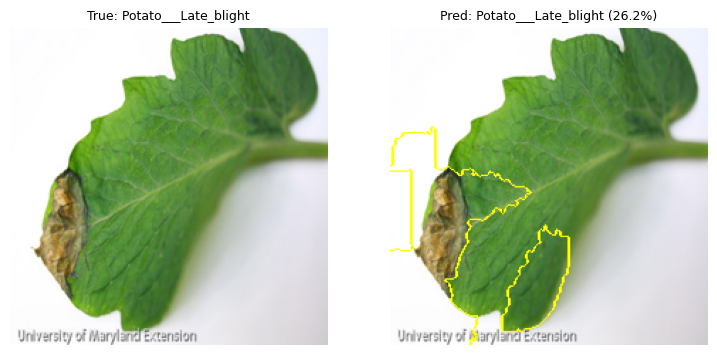

In [ ]:
out_dir = "/content/drive/MyDrive/AgroScan-data-V2/lime_figures"
os.makedirs(out_dir, exist_ok=True)

picks = [55, 17, 18]
names = ["correct", "misclassified", "low_confidence"]

explainer = lime_image.LimeImageExplainer()

for i in range(len(picks)):
    path = test_imgs[picks[i]][0]
    true_label = test_imgs[picks[i]][1]
    im = load_img(path)
    exp = explainer.explain_instance(im, predict_fn, top_labels=1,
                                     hide_color=0, num_samples=1000)
    lbl = exp.top_labels[0]
    pr = predict_fn(np.expand_dims(im, axis=0))[0]
    t, m = exp.get_image_and_mask(lbl, positive_only=True,
                                  num_features=5, hide_rest=False)

    fig, axes = plt.subplots(1, 2, figsize=(9, 4.5))
    axes[0].imshow(im)
    axes[0].set_title("True: " + true_label, fontsize=9)
    axes[1].imshow(mark_boundaries(t / 255.0, m))
    axes[1].set_title("Pred: " + CLASS_NAMES[lbl] + " (" + str(round(float(pr[lbl]) * 100, 1)) + "%)", fontsize=9)
    for j in range(len(axes)):
        axes[j].axis("off")
    plt.savefig(out_dir + "/lime_" + names[i] + ".png", dpi=150, bbox_inches="tight")
    plt.show()